# Day 2 — Visual Content Representation

Load the PDF, extract its text, tables and figures, then caption and embed the visual content. Text and tables are split into chunks for later indexing.

## 1. Install dependencies

Install the document parsing, text-splitting, vision-language model, and CLIP libraries.

In [1]:
!apt-get -qq update
!apt-get -qq install -y poppler-utils
!pip -q install "unstructured[pdf]" pymupdf pillow pandas matplotlib transformers accelerate sentencepiece langchain-text-splitters

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../libpoppler-private-dev_24.02.0-1ubuntu9.11_amd64.deb ...
Unpacking libpoppler-private-dev:amd64 (24.02.0-1ubuntu9.11) over (24.02.0-1ubuntu9.10) ...
Preparing to unpack .../libpoppler-dev_24.02.0-1ubuntu9.11_amd64.deb ...
Unpacking libpoppler-dev:amd64 (24.02.0-1ubuntu9.11) over (24.02.0-1ubuntu9.10) ...
Preparing to unpack .../libpoppler134_24.02.0-1ubuntu9.11_amd64.deb ...
Unpacking libpoppler134:amd64 (24.02.0-1ubuntu9.11) over (24.02.0-1ubuntu9.10) ...
Selecting previously unselected package poppler-utils.
Preparing to unpack .../poppler-utils_24.02.0-1ubuntu9.11_amd64.deb ...
Unpacking poppler-utils (24.02.0-1ubuntu9.11) ...
Setting up libpoppler134:amd64 (24.02.0-1ubuntu9.11) ...
Setting up poppler-

## 2. Imports and device

Import the libraries and check whether a GPU is available.

In [2]:
from pathlib import Path
import json
import torch
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import fitz

from unstructured.partition.pdf import partition_pdf
from langchain_text_splitters import RecursiveCharacterTextSplitter
from transformers import (
    Blip2Processor, Blip2ForConditionalGeneration,
    CLIPProcessor, CLIPModel
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Device: cuda
GPU: Tesla T4


## 3. Upload a PDF

Upload the same sample invoice used in Day 1, or another PDF containing figures and tables.

In [3]:
from google.colab import files

uploaded = files.upload()
pdf_files = [name for name in uploaded if name.lower().endswith(".pdf")]
if not pdf_files:
    raise ValueError("Upload a PDF file.")

pdf_path = Path(pdf_files[0])
print("Using:", pdf_path.name)

Saving sample_multimodal_invoice.pdf to sample_multimodal_invoice.pdf
Using: sample_multimodal_invoice.pdf


## 4. Extract document elements and image blocks

Parse the PDF and save image and table regions as image files for visual processing.

In [4]:
image_dir = Path("day2_extracted_images")
image_dir.mkdir(exist_ok=True)

elements = partition_pdf(
    filename=str(pdf_path),
    strategy="hi_res",
    infer_table_structure=True,
    extract_images_in_pdf=True,
    extract_image_block_types=["Image", "Table"],
    extract_image_block_output_dir=str(image_dir)
)

print("Elements extracted:", len(elements))
print("Image files found:", len(list(image_dir.glob("*"))))

yolox_l0.05.onnx: reconstructing file:   0%|          |  0.00B /  217MB            

yolox_l0.05.onnx: downloading bytes:           |  0.00B            

preprocessor_config.json:   0%|          | 0.00/274 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.47k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  115MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/367 [00:00<?, ?it/s]

Elements extracted: 35
Image files found: 6


## 5. Collect text and table content

Keep text and table elements with their page number and source-document metadata.

In [5]:
text_records = []

for element_id, element in enumerate(elements):
    category = element.category
    if category in ["NarrativeText", "Title", "ListItem", "Text", "Table"]:
        text = str(element).strip()
        if text:
            text_records.append({
                "element_id": element_id,
                "source_doc": pdf_path.name,
                "page": element.metadata.page_number,
                "type": "table" if category == "Table" else "text",
                "text": text
            })

text_df = pd.DataFrame(text_records)
display(text_df.head(10))
print("Text/table elements:", len(text_records))

,element_id,source_doc,page,type,text
0,1,sample_multimodal_invoice.pdf,1,text,TAX INVOICE
1,2,sample_multimodal_invoice.pdf,1,text,Original for recipient
2,4,sample_multimodal_invoice.pdf,1,text,Supplier
3,5,sample_multimodal_invoice.pdf,1,text,"Meridian Research Labs Pvt. Ltd. Plot 18, Sect..."
4,6,sample_multimodal_invoice.pdf,1,text,Bill To
5,7,sample_multimodal_invoice.pdf,1,text,"Northstar Office Supplies Unit 402, Tech Park ..."
6,8,sample_multimodal_invoice.pdf,1,table,Invoice No. MRL-2026-1184 Invoice Date 18 Nov ...
7,9,sample_multimodal_invoice.pdf,1,text,Items and Services
8,10,sample_multimodal_invoice.pdf,1,table,# Description HSN/SAC Qty Unit Price (n) Amoun...
9,11,sample_multimodal_invoice.pdf,1,text,SGST (9%)


Text/table elements: 30


## 6. Split text and tables into chunks

Use separate chunk sizes for regular text and tables so table rows are less likely to be separated from their context.

In [6]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=700,
    chunk_overlap=100,
    separators=["\n\n", "\n", ". ", " ", ""]
)

table_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=150,
    separators=["\n", "|", " ", ""]
)

text_chunks = []
for record in text_records:
    splitter = table_splitter if record["type"] == "table" else text_splitter
    for chunk_number, chunk in enumerate(splitter.split_text(record["text"])):
        text_chunks.append({
            "chunk_id": f"{record['element_id']}_{chunk_number}",
            "source_doc": record["source_doc"],
            "page": record["page"],
            "type": record["type"],
            "text": chunk
        })

chunks_df = pd.DataFrame(text_chunks)
display(chunks_df.head(10))
print("Total chunks:", len(text_chunks))

,chunk_id,source_doc,page,type,text
0,1_0,sample_multimodal_invoice.pdf,1,text,TAX INVOICE
1,2_0,sample_multimodal_invoice.pdf,1,text,Original for recipient
2,4_0,sample_multimodal_invoice.pdf,1,text,Supplier
3,5_0,sample_multimodal_invoice.pdf,1,text,"Meridian Research Labs Pvt. Ltd. Plot 18, Sect..."
4,6_0,sample_multimodal_invoice.pdf,1,text,Bill To
5,7_0,sample_multimodal_invoice.pdf,1,text,"Northstar Office Supplies Unit 402, Tech Park ..."
6,8_0,sample_multimodal_invoice.pdf,1,table,Invoice No. MRL-2026-1184 Invoice Date 18 Nov ...
7,9_0,sample_multimodal_invoice.pdf,1,text,Items and Services
8,10_0,sample_multimodal_invoice.pdf,1,table,# Description HSN/SAC Qty Unit Price (n) Amoun...
9,11_0,sample_multimodal_invoice.pdf,1,text,SGST (9%)


Total chunks: 30


## 7. Find extracted image files

List the image blocks saved during PDF parsing and load them as RGB images.

In [7]:
image_extensions = {".png", ".jpg", ".jpeg", ".webp", ".bmp"}
image_paths = sorted(
    p for p in image_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)

image_items = []
for image_id, image_path in enumerate(image_paths):
    try:
        image = Image.open(image_path).convert("RGB")
        image_items.append({
            "image_id": image_id,
            "source_doc": pdf_path.name,
            "image_path": str(image_path),
            "image": image
        })
    except Exception as error:
        print("Skipped", image_path.name, error)

print("Usable images:", len(image_items))

Usable images: 6


## 8. Preview extracted images

Inspect the extracted visual regions before captioning and embedding them.

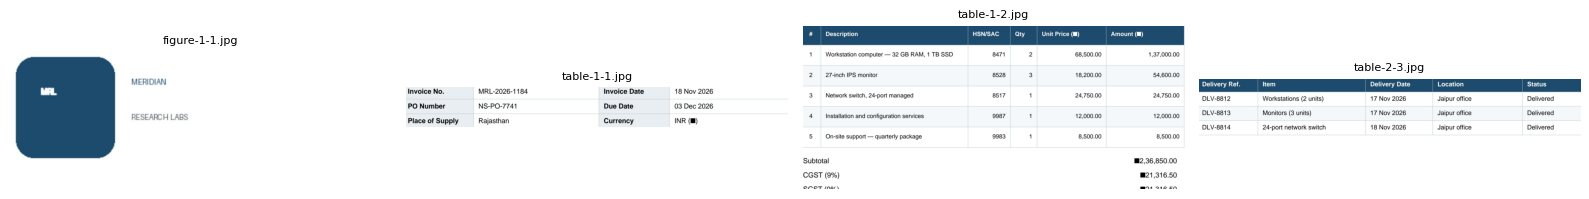

In [8]:
if image_items:
    fig, axes = plt.subplots(1, min(4, len(image_items)), figsize=(4 * min(4, len(image_items)), 4))
    if len(image_items) == 1:
        axes = [axes]
    for ax, item in zip(axes, image_items[:4]):
        ax.imshow(item["image"])
        ax.set_title(Path(item["image_path"]).name, fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No embedded image blocks were extracted from this PDF.")

## 9. Load the captioning model

Load the BLIP-2 model used in Module 5. It can require substantial GPU memory.

In [9]:
caption_model_id = "Salesforce/blip2-opt-2.7b"

caption_processor = Blip2Processor.from_pretrained(caption_model_id)
caption_model = Blip2ForConditionalGeneration.from_pretrained(
    caption_model_id,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    device_map="auto" if device == "cuda" else None
)

if device == "cpu":
    caption_model = caption_model.to(device)

print("Captioning model loaded:", caption_model_id)

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/882 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

... (3 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/1247 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

Captioning model loaded: Salesforce/blip2-opt-2.7b


## 10. Generate captions

Generate a natural-language caption for each extracted image and keep its document metadata.

In [10]:
@torch.inference_mode()
def generate_caption(image, max_new_tokens=80):
    inputs = caption_processor(images=image, return_tensors="pt")
    inputs = {key: value.to(caption_model.device) for key, value in inputs.items()}
    if "pixel_values" in inputs:
        inputs["pixel_values"] = inputs["pixel_values"].to(
            dtype=caption_model.dtype
        )
    output = caption_model.generate(**inputs, max_new_tokens=max_new_tokens)
    return caption_processor.decode(output[0], skip_special_tokens=True).strip()

for item in image_items:
    item["caption"] = generate_caption(item["image"])
    print(item["image_id"], item["caption"])

0 a blue and white graphic with the words medium and large
1 the table shows the different types of products that are available
2 the table shows the total number of employees and the number of employees
3 the table shows the different dates for each location
4 table showing the different types of services
5 a series of different types of lines in different colors


## 11. Load CLIP

Load CLIP to map images and text into a shared embedding space.

In [11]:
clip_model_id = "openai/clip-vit-base-patch32"
clip_processor = CLIPProcessor.from_pretrained(clip_model_id)
clip_model = CLIPModel.from_pretrained(clip_model_id).to(device)
clip_model.eval()

print("CLIP model loaded:", clip_model_id)

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP model loaded: openai/clip-vit-base-patch32


## 12. Create image embeddings

Create normalized CLIP vectors for the extracted images.

In [12]:
@torch.inference_mode()
def embed_images(images, batch_size=8):
    vectors = []
    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size]
        inputs = clip_processor(images=batch, return_tensors="pt").to(device)
        outputs = clip_model.vision_model(pixel_values=inputs["pixel_values"])
        pooled = outputs.pooler_output
        features = clip_model.visual_projection(pooled)
        vectors.append(F.normalize(features, p=2, dim=-1).cpu())
    if not vectors:
        return torch.empty((0, clip_model.config.projection_dim))
    return torch.cat(vectors, dim=0)

image_embeddings = embed_images([item["image"] for item in image_items])
print("Image embeddings:", image_embeddings.shape)

Image embeddings: torch.Size([6, 512])


## 13. Create text embeddings for captions and chunks

Embed captions and text/table chunks with CLIP so they can be compared with image vectors.

In [13]:
import torch
import torch.nn.functional as F

In [14]:
@torch.inference_mode()
def embed_texts(texts, batch_size=16):
    vectors = []
    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        inputs = clip_processor(
            text=batch, return_tensors="pt",
            padding=True, truncation=True
        ).to(device)
        outputs = clip_model.text_model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )
        pooled = outputs.pooler_output
        features = clip_model.text_projection(pooled)
        vectors.append(F.normalize(features, p=2, dim=-1).cpu())
    if not vectors:
        return torch.empty((0, clip_model.config.projection_dim))
    return torch.cat(vectors, dim=0)

captions = [item["caption"] for item in image_items]
chunk_texts = [item["text"] for item in text_chunks]

caption_embeddings = embed_texts(captions)
chunk_embeddings = embed_texts(chunk_texts)

print("Caption embeddings:", caption_embeddings.shape)
print("Text/table chunk embeddings:", chunk_embeddings.shape)

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Caption embeddings: torch.Size([6, 512])
Text/table chunk embeddings: torch.Size([30, 512])


## 14. Build metadata records

Store each image caption and its vector position alongside the source filename and image path.

In [15]:
image_records = []
for index, item in enumerate(image_items):
    image_records.append({
        "image_id": item["image_id"],
        "source_doc": item["source_doc"],
        "image_path": item["image_path"],
        "caption": item["caption"],
        "embedding_index": index
    })

for index, record in enumerate(text_chunks):
    record["embedding_index"] = index

print("Image records:", len(image_records))
print("Text/table chunk records:", len(text_chunks))

Image records: 6
Text/table chunk records: 30


## 15. Compare captions with extracted text

Review captions and text chunks together to check whether the captions add useful visual information.

In [16]:
for item in image_records:
    print(f"Image {item['image_id']}: {item['caption']}")
    print("File:", item["image_path"])
    print()

display(chunks_df[["chunk_id", "page", "type", "text"]].head(8))

Image 0: a blue and white graphic with the words medium and large
File: day2_extracted_images/figure-1-1.jpg

Image 1: the table shows the different types of products that are available
File: day2_extracted_images/table-1-1.jpg

Image 2: the table shows the total number of employees and the number of employees
File: day2_extracted_images/table-1-2.jpg

Image 3: the table shows the different dates for each location
File: day2_extracted_images/table-2-3.jpg

Image 4: table showing the different types of services
File: day2_extracted_images/table-2-4.jpg

Image 5: a series of different types of lines in different colors
File: day2_extracted_images/table-2-5.jpg



,chunk_id,page,type,text
0,1_0,1,text,TAX INVOICE
1,2_0,1,text,Original for recipient
2,4_0,1,text,Supplier
3,5_0,1,text,"Meridian Research Labs Pvt. Ltd. Plot 18, Sect..."
4,6_0,1,text,Bill To
5,7_0,1,text,"Northstar Office Supplies Unit 402, Tech Park ..."
6,8_0,1,table,Invoice No. MRL-2026-1184 Invoice Date 18 Nov ...
7,9_0,1,text,Items and Services


## 16. Save representations and metadata

Save captions, chunk metadata, and CLIP vectors so they can be indexed in the next module day.

In [17]:
output_dir = Path("day2_outputs")
output_dir.mkdir(exist_ok=True)

with open(output_dir / "image_captions_metadata.json", "w", encoding="utf-8") as file:
    json.dump(image_records, file, ensure_ascii=False, indent=2)

with open(output_dir / "text_chunks_metadata.json", "w", encoding="utf-8") as file:
    json.dump(text_chunks, file, ensure_ascii=False, indent=2)

torch.save({
    "image_embeddings": image_embeddings,
    "caption_embeddings": caption_embeddings,
    "chunk_embeddings": chunk_embeddings
}, output_dir / "multimodal_embeddings.pt")

print("Saved outputs to:", output_dir)

Saved outputs to: day2_outputs


## 17. Download outputs

Download the metadata and embedding files for use in the indexing notebook.

In [18]:
from google.colab import files

files.download(str(output_dir / "image_captions_metadata.json"))
files.download(str(output_dir / "text_chunks_metadata.json"))
files.download(str(output_dir / "multimodal_embeddings.pt"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notebook summary

This notebook extracts text, tables, and image regions from a PDF. It splits text and tables into chunks, generates captions for extracted images with BLIP-2, and creates CLIP embeddings for images, captions, and text chunks. It preserves source-document and image metadata and saves the captions, chunk records, and vectors for multimodal indexing.